In [1]:
#Environment and project paths
from pathlib import Path
import os, sys, random, json, time, copy, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.transforms import functional as TF

import os


In [2]:

from google.colab import drive
drive.mount('/content/drive')

%cd /content

# Remove the previous incomplete clone, if any
!rm -rf /content/repo

# Clone the specified branch
!git clone --branch vision-transformer --single-branch https://github.com/Teamoreteateo/CS3244-DeepWeeds.git /content/repo


Mounted at /content/drive
/content
Cloning into '/content/repo'...
remote: Enumerating objects: 123, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 123 (delta 10), reused 9 (delta 7), pack-reused 104 (from 1)
Receiving objects: 100% (123/123), 7.96 MiB | 4.41 MiB/s, done.
Resolving deltas: 100% (55/55), done.


In [3]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU Name: NVIDIA L4


In [4]:

%cd /content/repo

!pip install -q scikit-image

!git log --oneline -2

# Copy your dataset from Google Drive
!mkdir -p data
!cp /content/drive/MyDrive/CS3244-DeepWeeds/data/labels.csv data/labels.csv
!rsync -ah --info=progress2 \
  /content/drive/MyDrive/CS3244-DeepWeeds/data/images/ \
  /content/repo/data/images/
# Verify that the files exist
!ls -l data/labels.csv
!ls data/images | wc -l




/content/repo
0c25c64 (HEAD -> vision-transformer, origin/vision-transformer) Add files via upload
4b28f0a Add files via upload
        492.31M 100%   41.06kB/s    3:15:08 (xfr#17518, to-chk=0/17520)
-rw------- 1 root root 598898 Nov 10 08:11 data/labels.csv
17519


In [5]:

REPO_ROOT = Path.cwd().parent  # Current directory is notebooks
sys.path.insert(0, str(REPO_ROOT))


In [6]:


SEED = 42
VAL_FOLD = 0
SPLIT = "paper"
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0
EPOCHS_SCRATCH = 15
EPOCHS_HF = 5
USE_WEIGHTED_SAMPLING = True
USE_CUTMIX = False
CUTMIX_PROBABILITY = 0.5
LEARNING_RATE_SCRATCH = 3e-4
LEARNING_RATE_HF = 2e-5
WEIGHT_DECAY = 1e-4

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "splits" / "folds_paper.csv").exists() and (p / "data" / "images").is_dir():
            return p
    for p in candidates:
        if (p / "splits" / "folds_paper.csv").exists():
            return p
    raise FileNotFoundError(
        "Could not locate splits/folds_paper.csv. Run this notebook from the project/repository "
        "or set PROJECT_ROOT manually."
    )

PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
sys.path.insert(0, str(SRC_DIR))

# Reuse the project's shared data, transform, and metric implementations.
from src.data import load_folds_paper
from src.data_pipeline import get_dataloaders, apply_cutmix, DeepWeedsDataset, make_transforms
from torch.utils.data import DataLoader, WeightedRandomSampler
from src.metrics import evaluate as project_evaluate, log_result, summarise as project_summarise, SPECIES

IMG_DIR = PROJECT_ROOT / "data" / "images"
FOLDS_PATH = PROJECT_ROOT / "splits" / "folds_paper.csv"
RESULTS_PATH = PROJECT_ROOT / "results.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "vit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", PROJECT_ROOT)
print("Image directory:", IMG_DIR, "| exists:", IMG_DIR.is_dir())
print("Fold manifest:", FOLDS_PATH, "| exists:", FOLDS_PATH.exists())
print("Device:", device)
print("PyTorch:", torch.__version__)
assert VAL_FOLD in range(5)
assert IMG_DIR.is_dir(), f"Missing {IMG_DIR}. Download/unzip DeepWeeds images as instructed."
assert FOLDS_PATH.exists(), f"Missing {FOLDS_PATH}. Pull the committed split manifest first."

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()


Project root: /content/repo
Image directory: /content/repo/data/images | exists: True
Fold manifest: /content/repo/splits/folds_paper.csv | exists: True
Device: cuda
PyTorch: 2.14.1+cu130


## 2. Load the committed split and verify leakage


In [7]:
# Load paper folds
df = load_folds_paper()

fold_col = f"paper_fold{VAL_FOLD}"

assert fold_col in df.columns
assert not df["Filename"].duplicated().any()
assert df[fold_col].isin(["train", "val", "test"]).all()

# Use the paper's train/validation/test assignments
train_df = df.loc[df[fold_col] == "train"].copy()
val_df = df.loc[df[fold_col] == "val"].copy()
test_df = df.loc[df[fold_col] == "test"].copy()

# Preserve existing class order
classes = SPECIES
class_to_idx = {name: i for i, name in enumerate(classes)}
NUM_CLASSES = len(classes)

# Preserve existing transforms
train_dataset = DeepWeedsDataset(
    train_df, IMG_DIR, make_transforms(True), classes
)
val_dataset = DeepWeedsDataset(
    val_df, IMG_DIR, make_transforms(False), classes
)

# Preserve existing weighted sampling
sampler = None
if USE_WEIGHTED_SAMPLING:
    counts = train_dataset.df["Species"].value_counts()
    weights = (1.0 / train_dataset.df["Species"].map(counts)).to_numpy()

    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(weights, dtype=torch.double),
        num_samples=len(train_dataset),
        replacement=True,
    )

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=(sampler is None),
    sampler=sampler,
    num_workers=NUM_WORKERS,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

test_loader = None

# Verify splits
assert len(train_df) and len(val_df)
assert set(train_df["Filename"]).isdisjoint(val_df["Filename"])
assert set(train_df["Filename"]).isdisjoint(test_df["Filename"])
assert set(val_df["Filename"]).isdisjoint(test_df["Filename"])

print(f"Paper fold: {VAL_FOLD}")
print(
    f"Train: {len(train_df):,}; "
    f"validation: {len(val_df):,}; "
    f"held-out test excluded: {len(test_df):,}"
)
print("Classes:", classes)

display(pd.DataFrame({
    "train": train_df["Species"].value_counts().reindex(classes, fill_value=0),
    "validation": val_df["Species"].value_counts().reindex(classes, fill_value=0),
}))

Paper fold: 0
Train: 10,501; validation: 3,501; held-out test excluded: 3,507
Classes: ['Chinee apple', 'Lantana', 'Parkinsonia', 'Parthenium', 'Prickly acacia', 'Rubber vine', 'Siam weed', 'Snake weed', 'Negative']


,train,validation
Species,,
Chinee apple,674,225
Lantana,638,213
Parkinsonia,618,206
Parthenium,613,204
Prickly acacia,637,212
Rubber vine,605,202
Siam weed,644,215
Snake weed,609,203
Negative,5463,1821


## 3. Image transforms and datasets

Training augmentation follows the  `02_splits_augmentation.ipynb` / `src/data_pipeline.py` Both models use ImageNet normalization so the pretrained model receives its expected input scale.

In [8]:
# get_dataloaders() above uses make_transforms() and DeepWeedsDataset from src/data_pipeline.py.
# Training augmentation and validation preprocessing are therefore shared with the other project methods.
# DeepWeedsDataset returns (image_tensor, integer_label, filename).
xb_batch = next(iter(train_loader))
xb, yb = xb_batch[0], xb_batch[1]
print("Image batch:", tuple(xb.shape), "| labels:", tuple(yb.shape))
assert xb.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

Image batch: (16, 3, 224, 224) | labels: (16,)


## 4. Metrics and training utilities

We report accuracy, macro-F1, macro precision/recall, weighted-F1, and validation loss.

In [9]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix

# project_evaluate, log_result and project_summarise are imported from src/metrics.py above.
HAS_PROJECT_LOGGER = True

def evaluate_model(model, loader, criterion):
    model.eval()
    total_loss, total_n = 0.0, 0
    y_true, y_pred = [], []
    with torch.inference_mode():
        for batch in loader:
            images, labels = batch[0].to(device), batch[1].to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            n = labels.size(0)
            total_loss += loss.item() * n
            total_n += n
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    # Keep the notebook's existing metrics and add the canonical project evaluation.
    project_metrics = project_evaluate(y_true, y_pred)
    return {
        "loss": total_loss / max(total_n, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "project_macro_f1": project_metrics["macro_f1"],
        "project_weighted_f1": project_metrics["weighted_f1"],
        "weed_to_negative_rate": project_metrics["weed_to_negative_rate"],
        "project_per_class": project_metrics["per_class"],
        "project_cm": project_metrics["cm"],
        "project_cm_norm": project_metrics["cm_norm"],
        "y_true": y_true,
        "y_pred": y_pred,
    }

def train_model(model, train_loader, val_loader, epochs, lr, weight_decay, run_name,
                use_cutmix=False, cutmix_probability=0.5):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                  lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = []
    best_f1 = -1.0
    best_state = None
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, seen, correct = 0.0, 0, 0
        for batch in train_loader:
            images, labels = batch[0].to(device), batch[1].to(device)
            if use_cutmix:
                images, mixed_labels = apply_cutmix(
                    images, labels, NUM_CLASSES, probability=cutmix_probability, alpha=1.0
                )
                logits = model(images)
                if mixed_labels.ndim == 2:
                    loss = -(mixed_labels * torch.log_softmax(logits, dim=1)).sum(dim=1).mean()
                else:
                    loss = criterion(logits, mixed_labels)
            else:
                logits = model(images)
                loss = criterion(logits, labels)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            n = labels.size(0)
            running_loss += loss.item() * n
            seen += n
            correct += (logits.argmax(dim=1) == labels).sum().item()
        scheduler.step()
        val_metrics = evaluate_model(model, val_loader, criterion)
        row = {
            "epoch": epoch,
            "train_loss": running_loss / max(seen, 1),
            "train_accuracy": correct / max(seen, 1),
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "val_macro_precision": val_metrics["macro_precision"],
            "val_macro_recall": val_metrics["macro_recall"],
            "val_weighted_f1": val_metrics["weighted_f1"],
            "lr": optimizer.param_groups[0]["lr"],
        }
        history.append(row)
        print(f"{run_name} | epoch {epoch:02d}/{epochs} | "
              f"train loss {row['train_loss']:.4f} acc {row['train_accuracy']:.4f} | "
              f"val loss {row['val_loss']:.4f} acc {row['val_accuracy']:.4f} "
              f"macro-F1 {row['val_macro_f1']:.4f} weighted-F1 {row['val_weighted_f1']:.4f}")
        if row["val_macro_f1"] > best_f1:
            best_f1 = row["val_macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            torch.save({
                "model_state_dict": best_state,
                "run_name": run_name,
                "best_epoch": epoch,
                "best_val_macro_f1": best_f1,
                "classes": classes,
                "split": SPLIT,
                "val_fold": VAL_FOLD,
                "seed": SEED,
            }, OUTPUT_DIR / f"{run_name}_best.pt")
        scheduler.step if False else None

    if best_state is not None:
        model.load_state_dict(best_state)
    best_metrics = evaluate_model(model, val_loader, criterion)
    history_df = pd.DataFrame(history)
    history_df.to_csv(OUTPUT_DIR / f"{run_name}_history.csv", index=False)
    result_summary = {
        k: v for k, v in best_metrics.items()
        if k in ("loss", "accuracy", "macro_f1", "macro_precision", "macro_recall",
                 "weighted_f1", "project_macro_f1", "project_weighted_f1", "weed_to_negative_rate")
    }
    result_summary["best_val_macro_f1"] = best_f1
    result_summary["best_epoch"] = int(history_df.loc[history_df["val_macro_f1"].idxmax(), "epoch"])
    result_summary["n_train"] = len(train_dataset)
    result_summary["n_validation"] = len(val_dataset)
    result_summary["split"] = SPLIT
    result_summary["val_fold"] = VAL_FOLD
    result_summary["seed"] = SEED
    if HAS_PROJECT_LOGGER:
        try:
            # Project convention: log_result(model_name, split_scheme, params, summary)
            project_metrics = project_evaluate(best_metrics["y_true"], best_metrics["y_pred"])
            log_summary = project_summarise([project_metrics])
            log_result(run_name, "paper", {
                "source": "V3_deepweeds_vit_scratch_vs_hf_vit_b16",
                "fold_file": "folds_paper.csv",
                "val_fold": VAL_FOLD,
                "seed": SEED,
                "epochs": epochs,
                "batch_size": BATCH_SIZE,
                "lr": lr,
                "weight_decay": weight_decay,
                "weighted_sampling": USE_WEIGHTED_SAMPLING,
                "cutmix": use_cutmix,
            }, log_summary)
            print("Logged through metrics.log_result to project results.csv.")
        except Exception as exc:
            print("Project log_result call failed; see note below:", repr(exc))
            print("Metrics are saved in:", OUTPUT_DIR)
    else:
        print("Project logger unavailable; metrics are saved in outputs/vit, not appended to results.csv.")
    return model, history_df, result_summary


## 5. Model A — Vision Transformer trained from scratch

This is a small ViT built from scratch specifically for this dataset: 16×16 patches (196 patches at 224×224), learned class token and positional embeddings, 6 Transformer encoder layers, 8 attention heads, and a 9-class output head. No pretrained weights are loaded.

In [10]:
class ScratchViT(nn.Module):
    def __init__(self, num_classes, image_size=224, patch_size=16, embed_dim=384,
                 depth=6, num_heads=6, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        assert image_size % patch_size == 0
        self.patch_size = patch_size
        n_patches = (image_size // patch_size) ** 2
        self.patch_embed = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=depth, norm=nn.LayerNorm(embed_dim))
        self.head = nn.Sequential(nn.LayerNorm(embed_dim), nn.Dropout(dropout),
                                  nn.Linear(embed_dim, num_classes))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.kaiming_normal_(self.patch_embed.weight, mode="fan_out", nonlinearity="relu")
        if self.patch_embed.bias is not None:
            nn.init.zeros_(self.patch_embed.bias)
    def forward(self, x):
        x = self.patch_embed(x)                 # B, D, H/patch, W/patch
        x = x.flatten(2).transpose(1, 2)        # B, N, D
        cls = self.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat((cls, x), dim=1) + self.pos_embed
        x = self.pos_drop(x)
        x = self.encoder(x)
        return self.head(x[:, 0])

scratch_model = ScratchViT(NUM_CLASSES, image_size=IMAGE_SIZE, patch_size=16,
                           embed_dim=384, depth=6, num_heads=6, dropout=0.1)
print(scratch_model)
print(f"Trainable parameters: {sum(p.numel() for p in scratch_model.parameters() if p.requires_grad):,}")


ScratchViT(
  (patch_embed): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
  (pos_drop): Dropout(p=0.1, inplace=False)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=384, out_features=384, bias=True)
        )
        (linear1): Linear(in_features=384, out_features=1536, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=1536, out_features=384, bias=True)
        (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
    (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (head): Sequential(
    (0): LayerNorm((384,), eps=1e-05, element

/tmp/ipykernel_1475/2938882161.py:16: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=depth, norm=nn.LayerNorm(embed_dim))


In [11]:
scratch_model, scratch_history, scratch_summary = train_model(
    scratch_model, train_loader, val_loader,
    epochs=EPOCHS_SCRATCH,
    lr=LEARNING_RATE_SCRATCH,
    weight_decay=WEIGHT_DECAY,
    run_name="vit_scratch",
    use_cutmix=USE_CUTMIX,
    cutmix_probability=CUTMIX_PROBABILITY,
)
display(scratch_history.tail())
print("Best validation summary:", scratch_summary)


vit_scratch | epoch 01/15 | train loss 2.1423 acc 0.1787 | val loss 2.0388 acc 0.2179 macro-F1 0.1813 weighted-F1 0.1970
vit_scratch | epoch 02/15 | train loss 1.8019 acc 0.3164 | val loss 1.6519 acc 0.3533 macro-F1 0.3074 weighted-F1 0.3585
vit_scratch | epoch 03/15 | train loss 1.6045 acc 0.3982 | val loss 1.5294 acc 0.4245 macro-F1 0.3865 weighted-F1 0.4396
vit_scratch | epoch 04/15 | train loss 1.5124 acc 0.4348 | val loss 1.4332 acc 0.4599 macro-F1 0.4289 weighted-F1 0.4790
vit_scratch | epoch 05/15 | train loss 1.4282 acc 0.4615 | val loss 1.5769 acc 0.3973 macro-F1 0.3993 weighted-F1 0.3963
vit_scratch | epoch 06/15 | train loss 1.3695 acc 0.4942 | val loss 1.5430 acc 0.4102 macro-F1 0.4134 weighted-F1 0.4106
vit_scratch | epoch 07/15 | train loss 1.3033 acc 0.5200 | val loss 1.4480 acc 0.4539 macro-F1 0.4511 weighted-F1 0.4591
vit_scratch | epoch 08/15 | train loss 1.2654 acc 0.5337 | val loss 1.2850 acc 0.5327 macro-F1 0.5132 weighted-F1 0.5506
vit_scratch | epoch 09/15 | trai

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1,val_macro_precision,val_macro_recall,val_weighted_f1,lr
10,11,1.075579,0.610418,1.095712,0.589260,0.559168,0.524987,0.658418,0.602374,0.000050
11,12,1.016987,0.629845,1.100242,0.595830,0.567662,0.521127,0.676836,0.606709,0.000029
12,13,0.969333,0.650414,1.123484,0.586118,0.565462,0.532999,0.668930,0.599471,0.000013
13,14,0.949261,0.660413,1.014287,0.624393,0.595728,0.552116,0.696059,0.635735,0.000003
14,15,0.920488,0.671936,1.020785,0.624679,0.597699,0.553461,0.698772,0.635957,0.000000


Best validation summary: {'loss': 1.0207850580486493, 'accuracy': 0.6246786632390745, 'macro_f1': 0.5976991739405823, 'macro_precision': 0.5534613617036155, 'macro_recall': 0.6987718555879819, 'weighted_f1': 0.6359565461046827, 'project_macro_f1': 0.5976991739405823, 'project_weighted_f1': 0.6359565461046827, 'weed_to_negative_rate': np.float64(0.04702380952380952), 'best_val_macro_f1': 0.5976991739405823, 'best_epoch': 15, 'n_train': 10501, 'n_validation': 3501, 'split': 'paper', 'val_fold': 0, 'seed': 42}


## 6. Model B — Hugging Face pretrained ViT-B/16 fine-tuned on DeepWeeds

Uses Hugging Face checkpoint `google/vit-base-patch16-224-in21k`. The pretrained backbone is initialized from the public checkpoint, and the classifier is replaced with a 9-class head. This is **fine-tuning**, not frozen embeddings: all backbone parameters are trainable. Internet access is needed the first time unless the checkpoint is already cached.

In [12]:
# Install once if needed in the notebook environment:
# %pip install -U transformers safetensors

try:
    from transformers import ViTForImageClassification
except ImportError as exc:
    raise ImportError("Install Hugging Face Transformers first: %pip install -U transformers safetensors") from exc

HF_CHECKPOINT = "google/vit-base-patch16-224-in21k"
id2label = {i: name for i, name in enumerate(classes)}
label2id = {name: i for i, name in enumerate(classes)}

hf_model = ViTForImageClassification.from_pretrained(
    HF_CHECKPOINT,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)
# Verify all parameters are trainable for a full fine-tuning comparison.
for parameter in hf_model.parameters():
    parameter.requires_grad = True

class HFViTClassifier(nn.Module):
    def __init__(self, hf_model):
        super().__init__()
        self.hf_model = hf_model
    def forward(self, pixel_values):
        return self.hf_model(pixel_values=pixel_values).logits

hf_classifier = HFViTClassifier(hf_model)
print("Checkpoint:", HF_CHECKPOINT)
print("Trainable parameters:", f"{sum(p.numel() for p in hf_classifier.parameters() if p.requires_grad):,}")


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Checkpoint: google/vit-base-patch16-224-in21k
Trainable parameters: 85,805,577


In [13]:
hf_classifier, hf_history, hf_summary = train_model(
    hf_classifier, train_loader, val_loader,
    epochs=EPOCHS_HF,
    lr=LEARNING_RATE_HF,
    weight_decay=WEIGHT_DECAY,
    run_name="vit_hf_vit_base_patch16_224_in21k_finetuned",
    use_cutmix=USE_CUTMIX,
    cutmix_probability=CUTMIX_PROBABILITY,
)
display(hf_history.tail())
print("Best validation summary:", hf_summary)


vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 01/5 | train loss 1.0477 acc 0.7484 | val loss 0.6782 acc 0.8238 macro-F1 0.8080 weighted-F1 0.8281
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 02/5 | train loss 0.3713 acc 0.9148 | val loss 0.5110 acc 0.8478 macro-F1 0.8399 weighted-F1 0.8537
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 03/5 | train loss 0.2319 acc 0.9452 | val loss 0.3529 acc 0.8952 macro-F1 0.8812 weighted-F1 0.8971
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 04/5 | train loss 0.1753 acc 0.9593 | val loss 0.3210 acc 0.9092 macro-F1 0.9026 weighted-F1 0.9117
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 05/5 | train loss 0.1334 acc 0.9731 | val loss 0.2424 acc 0.9389 macro-F1 0.9267 weighted-F1 0.9397
Logged through metrics.log_result to project results.csv.


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1,val_macro_precision,val_macro_recall,val_weighted_f1,lr
0,1,1.047711,0.748405,0.678244,0.823765,0.808036,0.762192,0.882081,0.828124,0.000018
1,2,0.371254,0.914770,0.511029,0.847758,0.839914,0.800199,0.910793,0.853742,0.000013
2,3,0.231909,0.945243,0.352896,0.895173,0.881191,0.844232,0.931241,0.897139,0.000007
3,4,0.175300,0.959337,0.320984,0.909169,0.902605,0.867568,0.949096,0.911722,0.000002
4,5,0.133357,0.973145,0.242446,0.938875,0.926711,0.903224,0.952953,0.939677,0.000000


Best validation summary: {'loss': 0.24244589065311978, 'accuracy': 0.93887460725507, 'macro_f1': 0.9267114918431234, 'macro_precision': 0.9032243266967205, 'macro_recall': 0.952952763687892, 'weighted_f1': 0.9396770134705557, 'project_macro_f1': 0.9267114918431234, 'project_weighted_f1': 0.9396770134705557, 'weed_to_negative_rate': np.float64(0.009523809523809525), 'best_val_macro_f1': 0.9267114918431234, 'best_epoch': 5, 'n_train': 10501, 'n_validation': 3501, 'split': 'paper', 'val_fold': 0, 'seed': 42}


## 7. Compare validation results

These are validation results only; use them for model selection and error analysis, not as a final unbiased test estimate. The `is_test=True` set remains untouched.

,loss,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,best_epoch
model,,,,,,,
Hugging Face ViT-B/16 fine-tuned,0.242446,0.938875,0.926711,0.903224,0.952953,0.939677,5
ViT from scratch,1.020785,0.624679,0.597699,0.553461,0.698772,0.635957,15


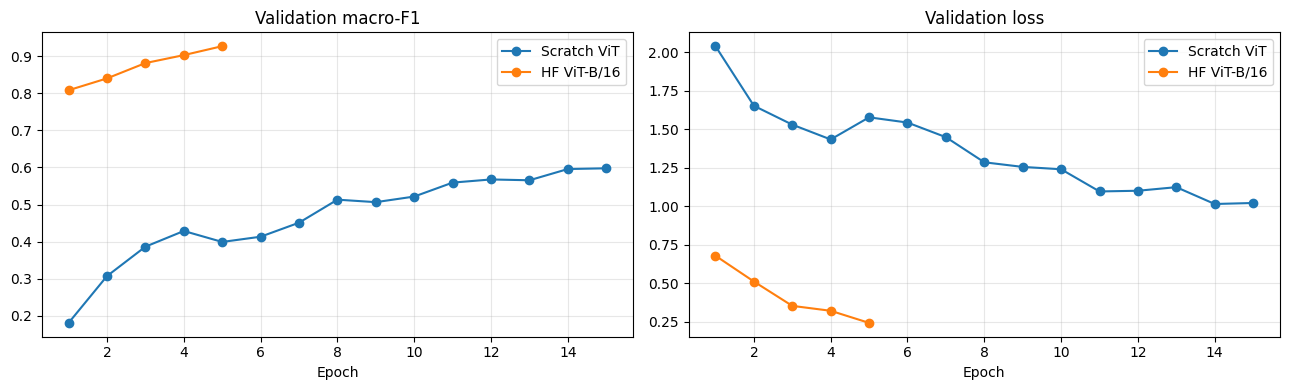

Saved outputs to: /content/repo/outputs/vit


In [14]:
comparison = pd.DataFrame([
    {"model": "ViT from scratch", **{k: v for k, v in scratch_summary.items()
                                    if k in ["loss", "accuracy", "macro_f1", "macro_precision",
                                             "macro_recall", "weighted_f1", "best_epoch"]}},
    {"model": "Hugging Face ViT-B/16 fine-tuned", **{k: v for k, v in hf_summary.items()
                                    if k in ["loss", "accuracy", "macro_f1", "macro_precision",
                                             "macro_recall", "weighted_f1", "best_epoch"]}},
]).set_index("model")
display(comparison.sort_values("macro_f1", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for hist, name in [(scratch_history, "Scratch ViT"), (hf_history, "HF ViT-B/16")]:
    axes[0].plot(hist["epoch"], hist["val_macro_f1"], marker="o", label=name)
    axes[1].plot(hist["epoch"], hist["val_loss"], marker="o", label=name)
axes[0].set_title("Validation macro-F1")
axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv")
print("Saved outputs to:", OUTPUT_DIR)


## 8. Validation error analysis

Per-class report and confusion matrices are generated on the validation fold only. Inspect these alongside macro-F1 because a high overall accuracy can hide poor performance on less frequent weed species.

\n========================================================================
Scratch ViT
                precision    recall  f1-score   support

  Chinee apple     0.4644    0.5511    0.5041       225
       Lantana     0.5149    0.7324    0.6047       213
   Parkinsonia     0.4815    0.8204    0.6068       206
    Parthenium     0.4395    0.6765    0.5328       204
Prickly acacia     0.7364    0.7642    0.7500       212
   Rubber vine     0.4490    0.8069    0.5770       202
     Siam weed     0.4423    0.8372    0.5788       215
    Snake weed     0.5278    0.5616    0.5442       203
      Negative     0.9255    0.5387    0.6810      1821

      accuracy                         0.6247      3501
     macro avg     0.5535    0.6988    0.5977      3501
  weighted avg     0.7247    0.6247    0.6360      3501



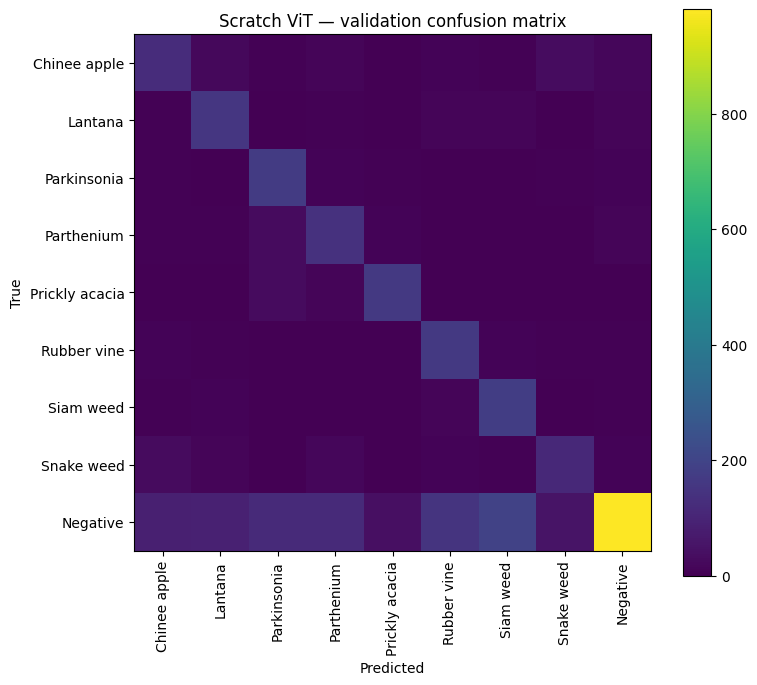

\n========================================================================
HF ViT-B/16
                precision    recall  f1-score   support

  Chinee apple     0.8340    0.9156    0.8729       225
       Lantana     0.9000    0.9718    0.9345       213
   Parkinsonia     0.9567    0.9660    0.9614       206
    Parthenium     0.9249    0.9657    0.9448       204
Prickly acacia     0.9067    0.9623    0.9336       212
   Rubber vine     0.9296    0.9802    0.9542       202
     Siam weed     0.8724    0.9860    0.9258       215
    Snake weed     0.8142    0.9064    0.8578       203
      Negative     0.9906    0.9226    0.9554      1821

      accuracy                         0.9389      3501
     macro avg     0.9032    0.9530    0.9267      3501
  weighted avg     0.9431    0.9389    0.9397      3501



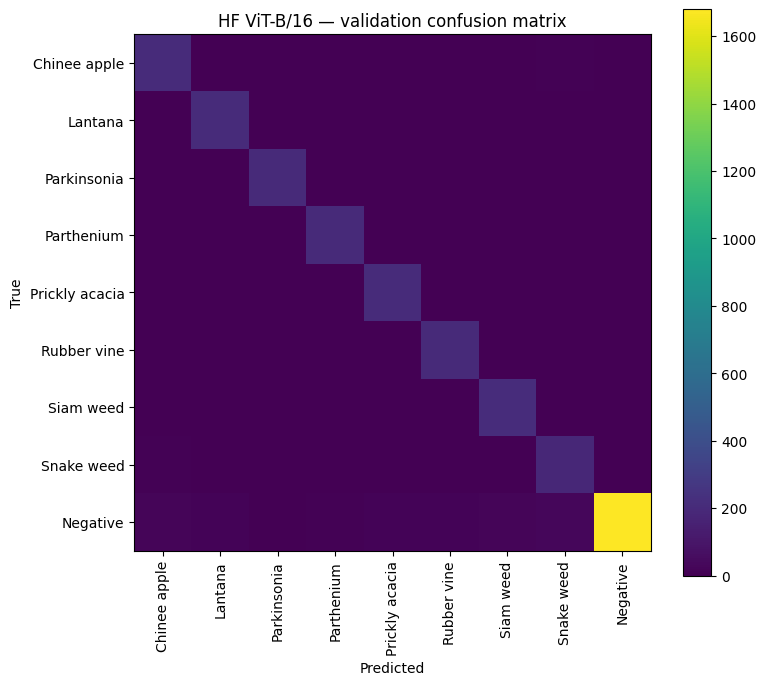

In [15]:
criterion = nn.CrossEntropyLoss()
scratch_eval = evaluate_model(scratch_model, val_loader, criterion)
hf_eval = evaluate_model(hf_classifier, val_loader, criterion)

for name, result in [("Scratch ViT", scratch_eval), ("HF ViT-B/16", hf_eval)]:
    print("\\n" + "=" * 72)
    print(name)
    print(classification_report(result["y_true"], result["y_pred"],
                                labels=list(range(NUM_CLASSES)), target_names=classes,
                                digits=4, zero_division=0))
    cm = confusion_matrix(result["y_true"], result["y_pred"], labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{name} — validation confusion matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks(range(NUM_CLASSES), classes, rotation=90)
    ax.set_yticks(range(NUM_CLASSES), classes)
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()
